In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from Preprocessing import preprocess

# Data set load
df_OG = pd.read_csv("heart_disease_health_indicators_BRFSS2015.csv")
# Drop of duplicates
df = df_OG.drop_duplicates().reset_index(drop=True)

Indicators = df.drop(columns="HeartDiseaseorAttack")
Ground_Truth = df["HeartDiseaseorAttack"]
GT_name = "HeartDiseaseorAttack"

# Training split
X_train, X_temp, Y_train, Y_temp = train_test_split(Indicators, Ground_Truth, train_size=0.50, stratify=Ground_Truth, random_state=25)
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.40, stratify=Y_temp, random_state=25)

for nombre, yy in [("Train", Y_train), ("Val", Y_val), ("Test", Y_test)]:
    print(f"{nombre}: {len(yy)/len(Ground_Truth):.0%} | "
          f"% positivos: {yy.mean():.2%}")


Train: 50% | % positivos: 10.32%
Val: 30% | % positivos: 10.32%
Test: 20% | % positivos: 10.32%


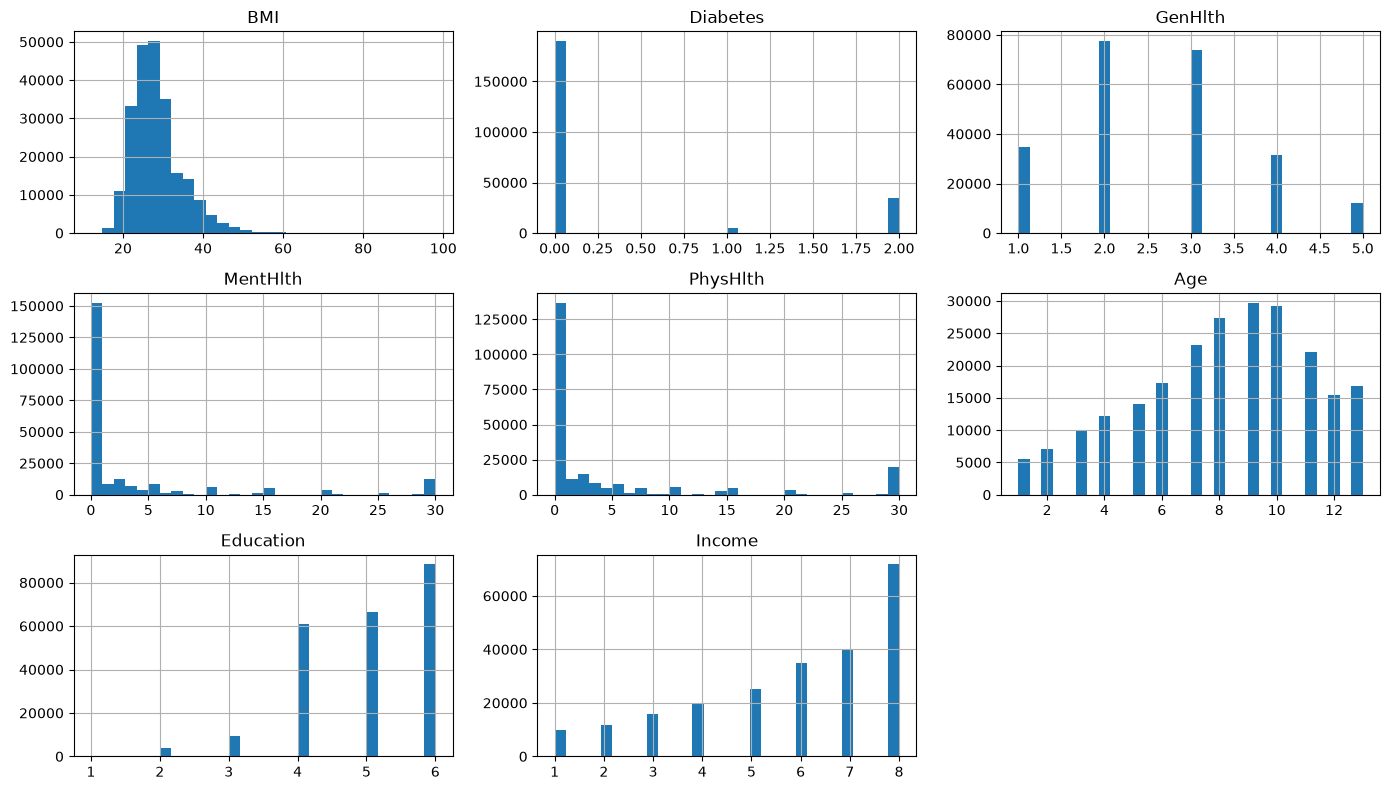

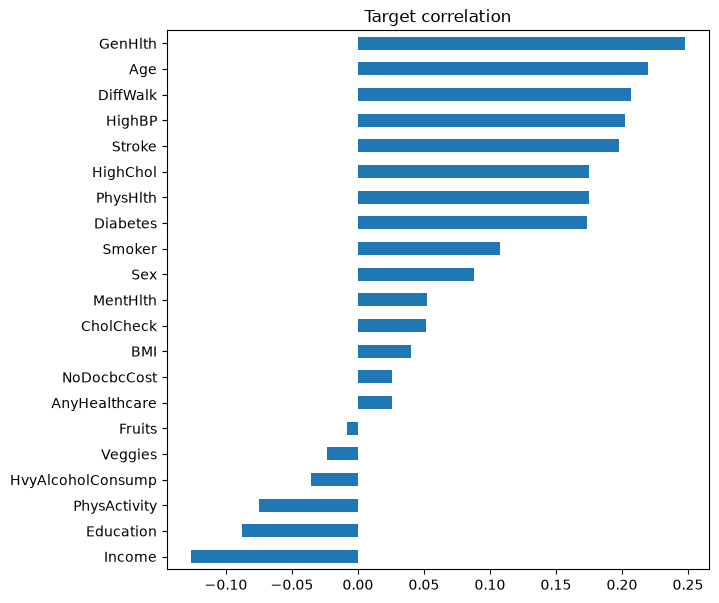

In [5]:
# Data visualisation
binary = [c for c in df.columns if df[c].nunique() == 2]
others = [c for c in df.columns if c not in binary]
df[others].hist(bins=30, figsize=(14, 8)); plt.tight_layout(); plt.show()
train = X_train.assign(**{GT_name: Y_train})

# Target correlation
corr = train.corr()[GT_name].drop(GT_name).sort_values()
corr.plot.barh(figsize=(7, 7), title="Target correlation"); plt.show()

In [ ]:
# Mutual information: captures nonlinear relations
discrete_features = [c != "BMI" for c in X_train.columns]
mi = pd.Series(mutual_info_classif(X_train, Y_train, discrete_features=discrete_features, random_state=25),
               index=X_train.columns)

# Random Forest (with class_weight for the unbalance)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=50,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=25)
rf.fit(X_train, Y_train)
rf_imp = pd.Series(rf.feature_importances_, index=X_train.columns)

# Permutation importance
perm = permutation_importance(rf, X_val, Y_val, scoring="average_precision",
                              n_repeats=10, n_jobs=-1, random_state=25)
perm_imp = pd.Series(perm.importances_mean, index=X_train.columns)

imp = pd.DataFrame({"mutual_info": mi, "random_forest": rf_imp, "permutation": perm_imp})
norm = imp.clip(lower=0)
norm = norm / norm.sum()

weights = {"mutual_info": 1, "random_forest": 1, "permutation": 2}
imp["score"] = sum(norm[c] * w for c, w in weights.items()) / sum(weights.values())

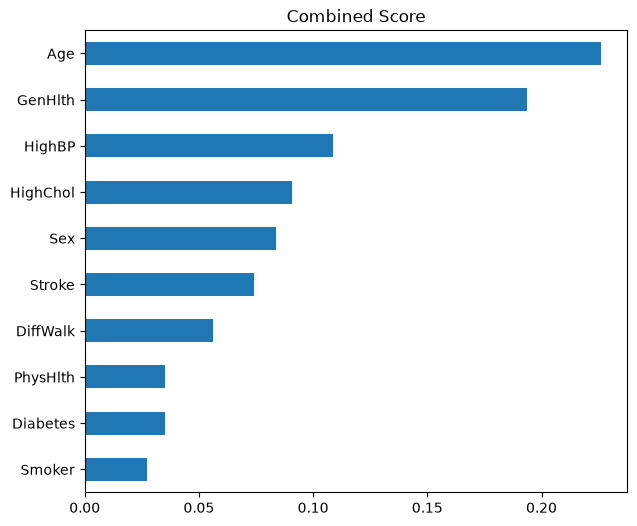

In [106]:
# Ranking formation
ranking = imp.sort_values("score", ascending=False)
top = ranking.head(10).index.tolist()

ranking["score"].head(10).sort_values().plot.barh(figsize=(7, 6), title="Combined Score")
plt.show()

# Most relevant Indicators
acum = ranking["score"].cumsum()
top_95 = acum[acum <= 0.95].index.tolist()
top_85 = acum[acum <= 0.85].index.tolist()
top_70 = acum[acum <= 0.70].index.tolist()

#print(top_95)
#print(top_85)
#print(top_70)

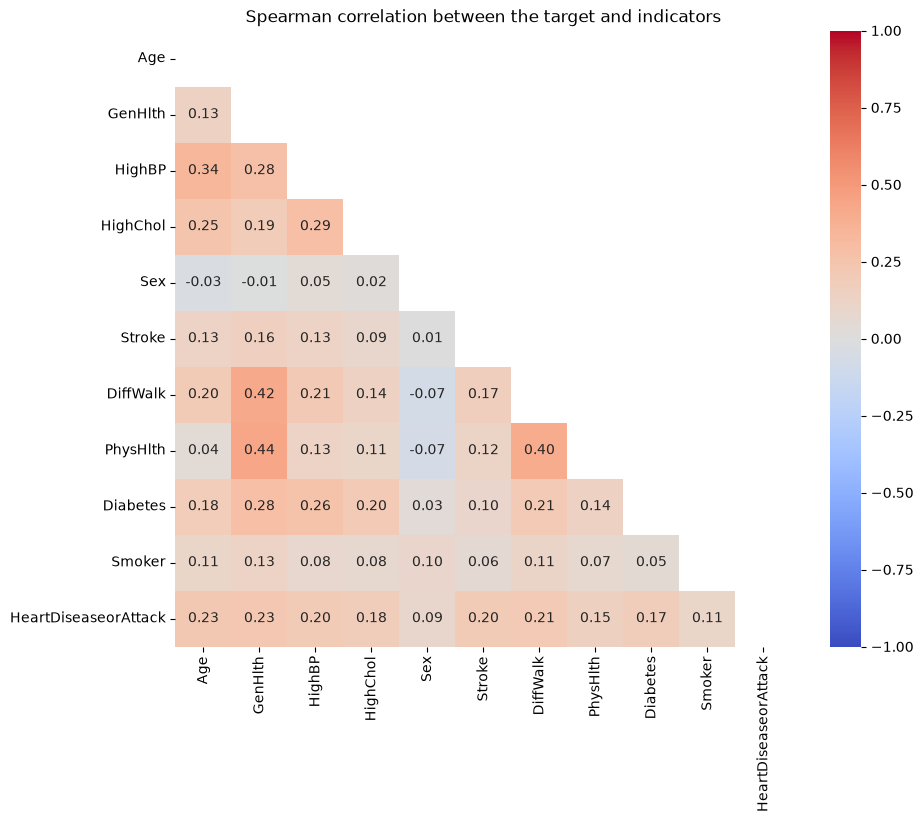

In [95]:
# Spearman correlation
corr_top = train[top + [GT_name]].corr(method="spearman")
mask = np.triu(np.ones_like(corr_top, dtype=bool))   # oculta la mitad redundante
plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation between the target and indicators")
plt.show()

In [2]:
ind = preprocess(df_OG)
top_95 = ind["top_95"]
df95 = df[top_95]
print(df95)

         Age  GenHlth  HighBP  HighChol  Sex  Stroke  DiffWalk  PhysHlth  \
0        9.0      5.0     1.0       1.0  0.0     0.0       1.0      15.0   
1        7.0      3.0     0.0       0.0  0.0     0.0       0.0       0.0   
2        9.0      5.0     1.0       1.0  0.0     0.0       1.0      30.0   
3       11.0      2.0     1.0       0.0  0.0     0.0       0.0       0.0   
4       11.0      2.0     1.0       1.0  0.0     0.0       0.0       0.0   
...      ...      ...     ...       ...  ...     ...       ...       ...   
229776   5.0      3.0     1.0       1.0  1.0     0.0       0.0       5.0   
229777  11.0      4.0     1.0       1.0  0.0     0.0       1.0       0.0   
229778   2.0      1.0     0.0       0.0  0.0     0.0       0.0       0.0   
229779   7.0      3.0     1.0       0.0  1.0     0.0       0.0       0.0   
229780   9.0      2.0     1.0       1.0  0.0     0.0       0.0       0.0   

        Diabetes  Smoker  
0            0.0     1.0  
1            0.0     1.0  
2     